# SEMMA — Cleveland Heart Disease Classification

This notebook demonstrates Sample, Explore, Modify, Model, and Assess. Upload `heart.csv` or `heart_disease.csv` to Colab, or place it in `data/raw/`. This is an educational prototype, not a diagnostic system.

In [1]:
from pathlib import Path
import warnings; warnings.filterwarnings('ignore')
import joblib, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report,roc_auc_score,average_precision_score,ConfusionMatrixDisplay
sns.set_theme(style='whitegrid'); RANDOM_STATE=42
candidates=list(Path('data/raw').glob('*.csv')) if Path('data/raw').exists() else []
candidates += [Path('/content/heart.csv'),Path('/content/heart_disease.csv')]
DATA_PATH=next((p for p in candidates if p.exists()),None)
if DATA_PATH is None: raise FileNotFoundError('Upload heart.csv or heart_disease.csv, or place it in data/raw/')
raw=pd.read_csv(DATA_PATH,na_values=['?']); print('Loaded',DATA_PATH,raw.shape); display(raw.head())

Loaded /content/heart.csv (302, 14)


,63.0,1.0,1.0.1,145.0,233.0,1.0.2,2.0,150.0,0.0,2.3,3.0,0.0.1,6.0,0
0,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
1,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
2,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
3,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0
4,56.0,1.0,2.0,120.0,236.0,0.0,0.0,178.0,0.0,0.8,1.0,0.0,3.0,0


## S — Sample

We create a stratified holdout sample so the class proportions are preserved.

In [2]:
# S — Sample
# Prepare a binary heart-disease target and create a stratified train/test split.

df = raw.copy()

# Standardize column names
df.columns = [
    str(column).strip().lower().replace(" ", "_")
    for column in df.columns
]

# Detect the target column
possible_targets = [
    "num",
    "target",
    "condition",
    "heartdisease",
    "heart_disease"
]

target = next(
    (column for column in possible_targets if column in df.columns),
    df.columns[-1]
)

print("Detected target column:", target)

# Convert numeric targets into binary:
# 0 = no heart disease
# values greater than 0 = heart disease
numeric_target = pd.to_numeric(df[target], errors="coerce")

if numeric_target.notna().mean() >= 0.90:
    valid_rows = numeric_target.notna()

    df = df.loc[valid_rows].copy()
    y = (numeric_target.loc[valid_rows] > 0).astype(int)

# Handle text-based targets such as yes/no or present/absent
else:
    text_target = (
        df[target]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    target_mapping = {
        "yes": 1,
        "true": 1,
        "positive": 1,
        "disease": 1,
        "present": 1,
        "no": 0,
        "false": 0,
        "negative": 0,
        "absent": 0
    }

    mapped_target = text_target.map(target_mapping)
    valid_rows = mapped_target.notna()

    df = df.loc[valid_rows].copy()
    y = mapped_target.loc[valid_rows].astype(int)

# Remove the target column from the predictors
X = df.drop(columns=[target])

# Remove an ID column if one exists
if "id" in X.columns:
    X = X.drop(columns=["id"])

# Create a stratified train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Final target values:", sorted(y.unique().tolist()))
print("\nTarget distribution:")
display(y.value_counts().rename("count").to_frame())

print("\nTraining shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining target values:", sorted(y_train.unique().tolist()))
print("Testing target values:", sorted(y_test.unique().tolist()))

Detected target column: 0
Final target values: [0, 1]

Target distribution:


,count
0,
0,163
1,139



Training shape: (241, 13)
Testing shape: (61, 13)

Training target values: [0, 1]
Testing target values: [0, 1]


## E — Explore

We inspect missingness, numeric distributions, and correlations with the outcome.

,dtype,missing,unique
63.0,float64,0,41
1.0,float64,0,2
1.0.1,float64,0,4
145.0,float64,0,50
233.0,float64,0,152
1.0.2,float64,0,2
2.0,float64,0,3
150.0,float64,0,91
0.0,float64,0,2
2.3,float64,0,40


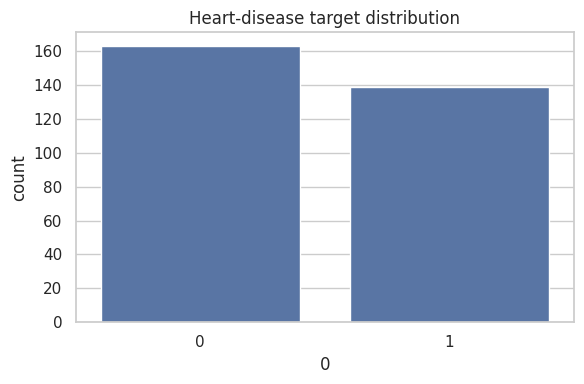

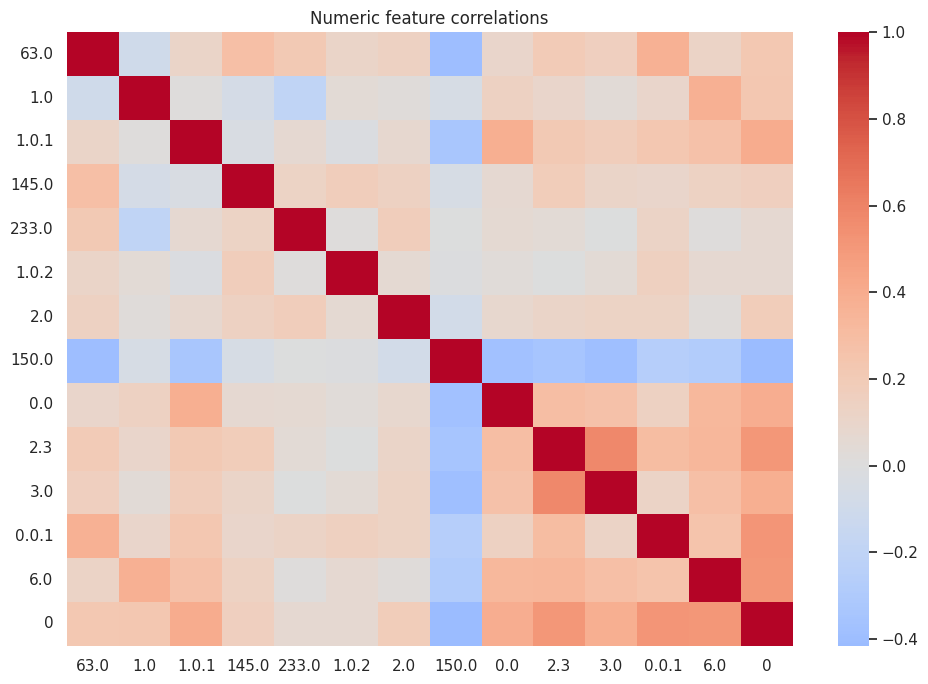

In [3]:
profile=pd.DataFrame({'dtype':df.dtypes.astype(str),'missing':df.isna().sum(),'unique':df.nunique()}); display(profile)
plt.figure(figsize=(6,4)); sns.countplot(x=y); plt.title('Heart-disease target distribution'); plt.tight_layout(); plt.show()
numeric=df.select_dtypes(include='number');
if numeric.shape[1]>1: plt.figure(figsize=(10,7)); sns.heatmap(numeric.corr(),cmap='coolwarm',center=0); plt.title('Numeric feature correlations'); plt.tight_layout(); plt.show()

## M — Modify

Numeric fields are median-imputed and scaled. Categorical fields are imputed and one-hot encoded inside a pipeline so test information does not leak into training.

In [4]:
num=X_train.select_dtypes(include='number').columns.tolist(); cat=[c for c in X_train.columns if c not in num]
pre=ColumnTransformer([('num',Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]),num),('cat',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore'))]),cat)])
models={'logistic_regression':LogisticRegression(max_iter=1000,class_weight='balanced',random_state=RANDOM_STATE),'decision_tree':DecisionTreeClassifier(max_depth=5,class_weight='balanced',random_state=RANDOM_STATE),'random_forest':RandomForestClassifier(n_estimators=300,class_weight='balanced',random_state=RANDOM_STATE,n_jobs=-1),'svm':SVC(probability=True,class_weight='balanced',random_state=RANDOM_STATE)}
ARTIFACTS=Path('artifacts'); ARTIFACTS.mkdir(exist_ok=True)

## M — Model and A — Assess

We compare four classifiers and assess discrimination plus class-specific errors. Recall is important because false negatives represent patients with disease that the model fails to flag.

,model,roc_auc,pr_auc,precision,recall,f1
0,logistic_regression,0.991342,0.990276,0.962963,0.928571,0.945455
3,svm,0.989177,0.988297,0.962963,0.928571,0.945455
2,random_forest,0.976190,0.974161,0.931034,0.964286,0.947368
1,decision_tree,0.887446,0.855690,0.774194,0.857143,0.813559


,precision,recall,f1-score,support
0,0.941176,0.969697,0.955224,33.00000
1,0.962963,0.928571,0.945455,28.00000
accuracy,0.950820,0.950820,0.950820,0.95082
macro avg,0.952070,0.949134,0.950339,61.00000
weighted avg,0.951177,0.950820,0.950740,61.00000


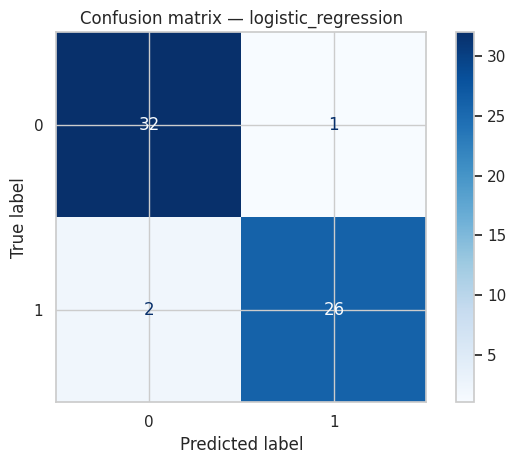

Saved artifacts to artifacts


In [5]:
rows=[]; fitted={}
for name,est in models.items():
    pipe=Pipeline([('preprocess',pre),('model',est)]); pipe.fit(X_train,y_train); p=pipe.predict_proba(X_test)[:,1]; pred=(p>=.5).astype(int); rep=classification_report(y_test,pred,output_dict=True,zero_division=0)
    rows.append({'model':name,'roc_auc':roc_auc_score(y_test,p),'pr_auc':average_precision_score(y_test,p),'precision':rep['1']['precision'],'recall':rep['1']['recall'],'f1':rep['1']['f1-score']}); fitted[name]=pipe
results=pd.DataFrame(rows).sort_values('roc_auc',ascending=False); results.to_csv(ARTIFACTS/'model_comparison.csv',index=False); display(results)
best_name=results.iloc[0]['model']; best=fitted[best_name]; pred=best.predict(X_test); display(pd.DataFrame(classification_report(y_test,pred,output_dict=True,zero_division=0)).T)
ConfusionMatrixDisplay.from_predictions(y_test,pred,cmap='Blues'); plt.title(f'Confusion matrix — {best_name}'); plt.tight_layout(); plt.savefig(ARTIFACTS/'confusion_matrix.png',dpi=180); plt.show(); joblib.dump(best,ARTIFACTS/'best_heart_disease_pipeline.joblib')
print('Saved artifacts to',ARTIFACTS)

## SEMMA conclusion

The final report should explain how sampling, exploration, modification, modeling, and assessment affected the result. This model is for coursework only and requires external validation, clinical review, and fairness analysis before any real-world use.